# Exploration des données : scouting football

Ce notebook montre la démarche : **que contiennent les données, sont-elles fiables, et que peut-on en tirer ?**
Il lit les fichiers produits par le pipeline (`data/processed/`), sans refaire la collecte.

Sources : FBref (statistiques de saison), Understat (xG, 5 grands championnats), Transfermarkt (valeurs, profils).
Plan : 1. qualité des données · 2. couverture · 3. valeur marchande · 4. joueurs marocains · 5. performance et valeur · 6. modèle de valeur · 7. conclusions.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 100})
pd.options.display.float_format = "{:,.1f}".format

racine = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = Path(os.environ.get("SCOUTING_DATA", racine / "data" / "processed"))

hist = pd.read_csv(DATA / "ml_base.csv.gz", dtype={"season": str}, low_memory=False)   # joueur x saison
modele = pd.read_csv(DATA / "valeur_predite.csv", dtype={"season": str})              # réel vs prédit
saison = hist["season"].max()
print(f"{len(hist):,} lignes joueur-saison, {hist['player'].nunique():,} joueurs, "
      f"saisons {hist['season'].min()} à {saison}, {hist['league'].nunique()} championnats")

33,302 lignes joueur-saison, 13,861 joueurs, saisons 2122 à 2526, 14 championnats


## 1. Qualité des données

D'abord, ce qui manque. Une valeur marchande absente est la principale limite du projet.

In [2]:
manquant = (hist.groupby("season")
            .agg(lignes=("player", "size"),
                 sans_valeur=("valeur_fin_saison_eur", lambda s: s.isna().mean() * 100),
                 sans_xg=("us_xg", lambda s: s.isna().mean() * 100)))
manquant.columns = ["lignes", "% sans valeur Transfermarkt", "% sans xG (Understat)"]
manquant

,lignes,% sans valeur Transfermarkt,% sans xG (Understat)
season,,,
2122,6769,13.0,59.2
2223,6591,11.4,59.1
2324,6620,9.9,59.5
2425,6662,10.2,59.8
2526,6660,8.5,60.0


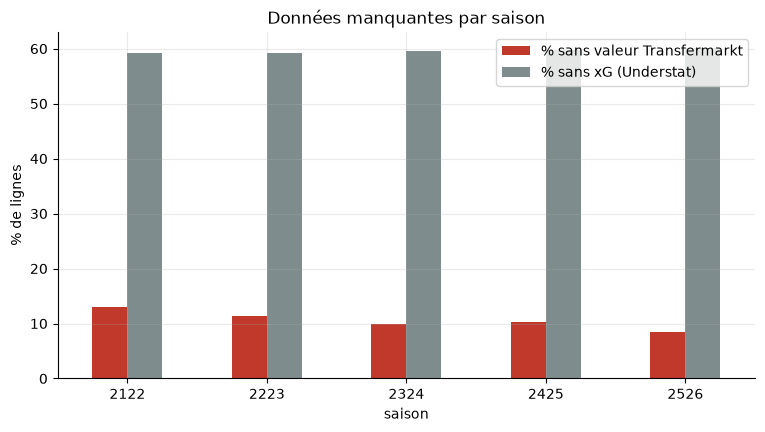

In [3]:
ax = manquant.iloc[:, 1:].plot.bar(color=["#c0392b", "#7f8c8d"])
ax.set_ylabel("% de lignes"); ax.set_xlabel("saison"); ax.set_title("Données manquantes par saison")
plt.xticks(rotation=0); plt.show()

**Lecture.** Les xG viennent d'Understat, qui ne couvre que les cinq grands championnats : leur absence ailleurs
est structurelle, pas un défaut de collecte. Les valeurs Transfermarkt manquent surtout pour les joueurs peu
utilisés ou de petits clubs. Les modèles et classements n'utilisent donc que les lignes avec valeur connue.

## 2. Couverture : championnats et âges

In [4]:
cur = hist[hist["season"] == saison]
par_ligue = cur.groupby("league").agg(joueurs=("player", "size"), age_moyen=("age", "mean"),
                                      valeur_mediane_meur=("valeur_fin_saison_eur", lambda s: s.median() / 1e6))
par_ligue.sort_values("joueurs", ascending=False)

,joueurs,age_moyen,valeur_mediane_meur
league,,,
ESP-La Liga,579,25.5,3.5
ITA-Serie A,560,25.3,5.0
POR-Primeira Liga,551,24.2,1.0
TUR-Super Lig,543,26.0,1.0
KSA-Pro League,518,26.3,0.5
NED-Eredivisie,518,23.9,1.0
FRA-Ligue 1,516,24.0,5.0
ENG-Premier League,507,24.9,20.0
GER-Bundesliga,474,24.8,5.0


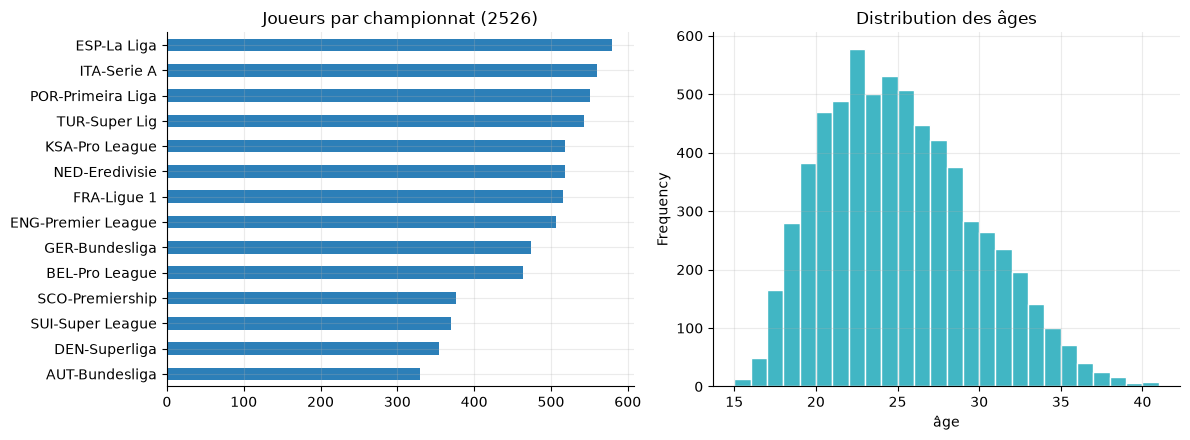

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
cur.groupby("league").size().sort_values().plot.barh(ax=ax[0], color="#2c7fb8")
ax[0].set_title(f"Joueurs par championnat ({saison})"); ax[0].set_ylabel("")
cur["age"].dropna().plot.hist(bins=range(15, 42), ax=ax[1], color="#41b6c4", edgecolor="white")
ax[1].set_title("Distribution des âges"); ax[1].set_xlabel("âge")
plt.tight_layout(); plt.show()

## 3. Valeur marchande

La valeur est très inégalement répartie : on regarde donc la distribution en échelle logarithmique.

médiane 1.8 M€, moyenne 6.8 M€, maximum 200 M€
Les 10 % de joueurs les plus chers concentrent 57% de la valeur totale.


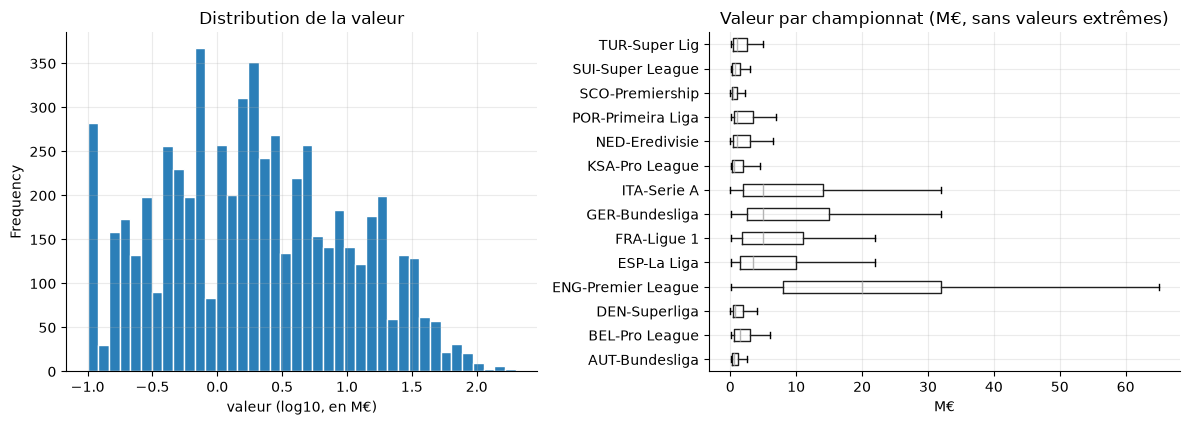

In [6]:
v = cur["valeur_fin_saison_eur"].dropna()
print(f"médiane {v.median() / 1e6:.1f} M€, moyenne {v.mean() / 1e6:.1f} M€, maximum {v.max() / 1e6:.0f} M€")
top10 = v.nlargest(max(1, int(len(v) * .1))).sum() / v.sum()
print(f"Les 10 % de joueurs les plus chers concentrent {top10:.0%} de la valeur totale.")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
np.log10(v.clip(lower=1e5) / 1e6).plot.hist(bins=40, ax=ax[0], color="#2c7fb8", edgecolor="white")
ax[0].set_xlabel("valeur (log10, en M€)"); ax[0].set_title("Distribution de la valeur")
cur.assign(v=cur["valeur_fin_saison_eur"] / 1e6).dropna(subset=["v"]).boxplot(
    column="v", by="league", ax=ax[1], vert=False, showfliers=False)
ax[1].set_title("Valeur par championnat (M€, sans valeurs extrêmes)"); ax[1].set_xlabel("M€"); ax[1].set_ylabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Lecture.** Une poignée de joueurs concentre l'essentiel de la valeur. La médiane est donc plus parlante que la moyenne, et c'est la raison de l'échelle logarithmique dans le modèle de valeur.

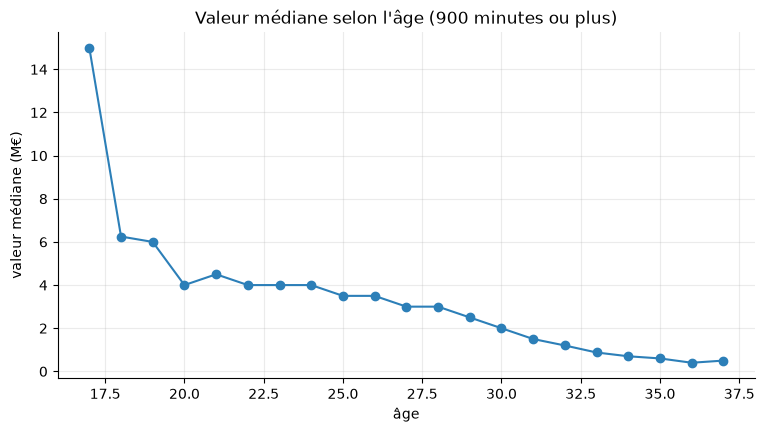

In [7]:
# valeur médiane selon l'âge : la courbe en cloche classique du marché des transferts
d = hist.dropna(subset=["age", "valeur_fin_saison_eur"]).query("playing_time_min >= 900")
d = d.assign(age_r=d["age"].round().clip(17, 37))
courbe = d.groupby("age_r")["valeur_fin_saison_eur"].agg(["median", "size"])
courbe = courbe[courbe["size"] >= 30]
ax = (courbe["median"] / 1e6).plot(marker="o", color="#2c7fb8")
ax.set_xlabel("âge"); ax.set_ylabel("valeur médiane (M€)"); ax.set_title("Valeur médiane selon l'âge (900 minutes ou plus)")
plt.show()

## 4. Joueurs marocains

Le projet cible les joueurs marocains : où jouent-ils, et quelle est leur valeur par rapport au reste ?

102 joueurs marocains en 2526 (1.5% de la base)


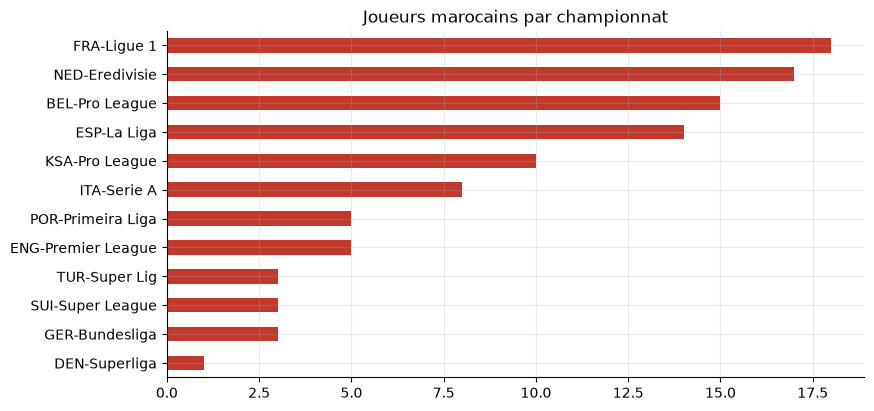

In [8]:
mar = cur[cur["is_moroccan"].astype(str).str.lower().isin(["true", "1"])]
print(f"{mar['player'].nunique()} joueurs marocains en {saison} ({len(mar) / len(cur):.1%} de la base)")
mar.groupby("league").size().sort_values().plot.barh(color="#c0392b")
plt.title("Joueurs marocains par championnat"); plt.ylabel(""); plt.show()

In [9]:
(mar.dropna(subset=["valeur_fin_saison_eur"]).sort_values("valeur_fin_saison_eur", ascending=False)
 .head(10)[["player", "team", "league", "age", "valeur_fin_saison_eur"]]
 .assign(valeur_meur=lambda x: x["valeur_fin_saison_eur"] / 1e6).drop(columns="valeur_fin_saison_eur"))

,player,team,league,age,valeur_meur
23904,Achraf Hakimi,Paris SG,FRA-Ligue 1,26.0,80.0
17206,Ayyoub Bouaddi,Lille,FRA-Ligue 1,17.0,50.0
29217,Ismael Saibari,PSV,NED-Eredivisie,24.0,40.0
29480,Abde Ezzalzouli,Real Betis,ESP-La Liga,23.0,40.0
11788,Bilal El Khannouss,Stuttgart,GER-Bundesliga,21.0,35.0
5056,Brahim Díaz,Real Madrid,ESP-La Liga,25.0,35.0
29668,Chemsdine Talbi,Sunderland,ENG-Premier League,20.0,25.0
14172,Neil El Aynaoui,Roma,ITA-Serie A,24.0,23.0
17378,Samir El Mourabet,Strasbourg,FRA-Ligue 1,19.0,22.0
9663,Amine Adli,Bournemouth,ENG-Premier League,25.0,20.0


## 5. La performance explique-t-elle la valeur ?

On teste le lien entre quelques statistiques par 90 minutes et la valeur, **par poste**, car un défenseur et un attaquant ne sont pas valorisés pour les mêmes raisons.

In [10]:
d = hist.query("playing_time_min >= 900").dropna(subset=["valeur_fin_saison_eur"]).copy()
d["log_valeur"] = np.log(d["valeur_fin_saison_eur"].clip(lower=1e5))
stats = [c for c in ["performance_gls_p90", "performance_ast_p90", "us_xg_p90", "us_xa_p90",
                     "performance_int_p90", "performance_tklw_p90", "age", "playing_time_min"] if c in d]
corr = (d.groupby("pos_main")[stats + ["log_valeur"]].corr()["log_valeur"].unstack()[stats]
        if "pos_main" in d else d[stats + ["log_valeur"]].corr()[["log_valeur"]].T)
corr.round(2)

,performance_gls_p90,performance_ast_p90,us_xg_p90,us_xa_p90,performance_int_p90,performance_tklw_p90,age,playing_time_min
pos_main,,,,,,,,
DF,0.1,0.1,0.2,0.1,-0.1,0.0,-0.3,0.2
FW,0.4,0.3,0.1,0.3,-0.0,-0.1,-0.3,0.3
GK,-0.0,0.0,-0.0,0.1,-0.0,-0.1,-0.4,0.3
MF,0.3,0.2,0.2,0.2,-0.1,-0.1,-0.3,0.2


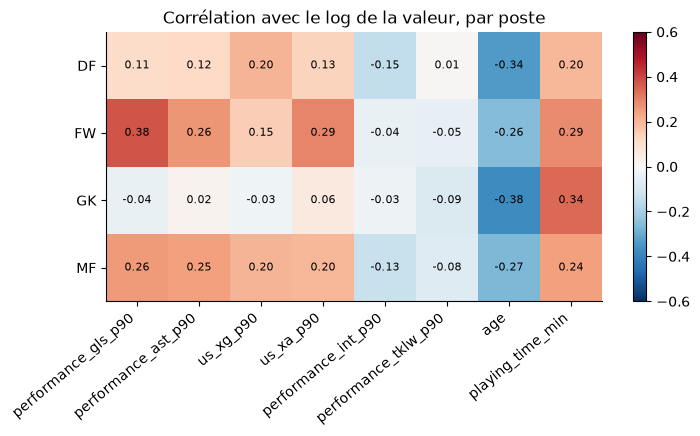

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-.6, vmax=.6, aspect="auto")
ax.set_xticks(range(corr.shape[1])); ax.set_xticklabels(corr.columns, rotation=40, ha="right")
ax.set_yticks(range(corr.shape[0])); ax.set_yticklabels(corr.index); ax.grid(False)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Corrélation avec le log de la valeur, par poste"); plt.colorbar(im); plt.show()

**Lecture.** Les buts et les xG par 90 minutes sont liés à la valeur des attaquants et des milieux, beaucoup moins à celle
des défenseurs. Les corrélations restent modestes : la valeur dépend aussi du club, de l'âge, de la notoriété et du contrat,
que les statistiques de saison ne capturent pas. C'est ce qui motive un modèle qui ajoute ces variables de contexte.

## 6. Le modèle de valeur : réel contre prédit

Dernière saison : 4,238 joueurs, erreur médiane absolue 32 %, 72% des estimations à ±50 %


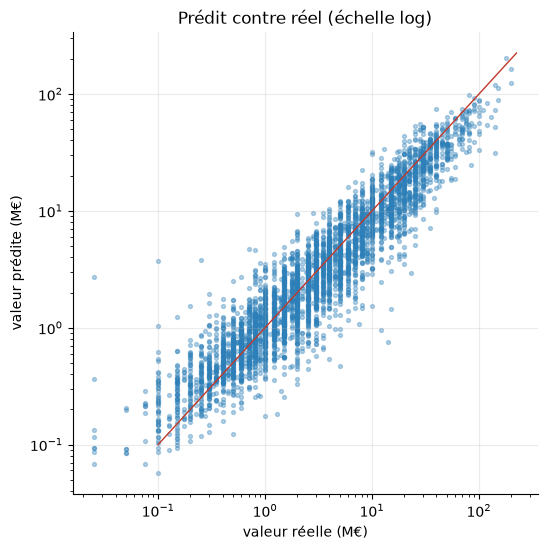

In [12]:
m = modele.dropna(subset=["valeur_reelle_eur", "valeur_predite_eur"]).copy()
m["err_pct"] = (m["valeur_predite_eur"] / m["valeur_reelle_eur"] - 1) * 100
last = m[m["season"] == m["season"].max()]
print(f"Dernière saison : {len(last):,} joueurs, erreur médiane absolue {last['err_pct'].abs().median():.0f} %, "
      f"{(last['err_pct'].abs() <= 50).mean():.0%} des estimations à ±50 %")
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(last["valeur_reelle_eur"] / 1e6, last["valeur_predite_eur"] / 1e6, s=8, alpha=.35, color="#2c7fb8")
lim = [0.1, max(last["valeur_reelle_eur"].max(), last["valeur_predite_eur"].max()) / 1e6 * 1.1]
ax.plot(lim, lim, color="#c0392b", lw=1); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("valeur réelle (M€)"); ax.set_ylabel("valeur prédite (M€)"); ax.set_title("Prédit contre réel (échelle log)")
plt.show()

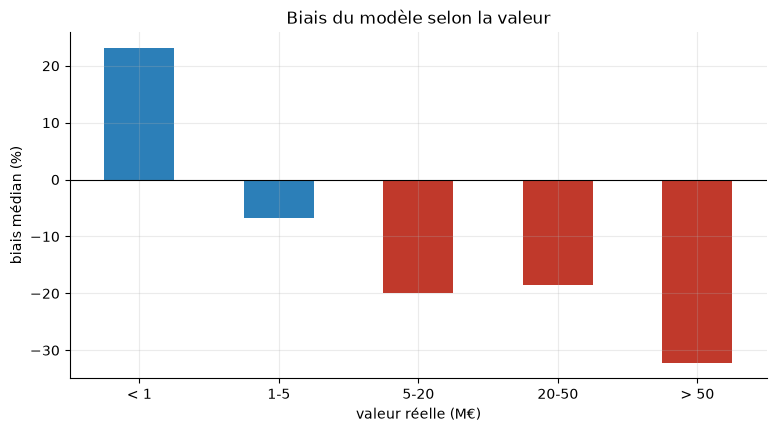

,biais médian (%),joueurs
valeur_reelle_eur,,
< 1,23.2,1276
1-5,-6.8,1497
5-20,-20.0,958
20-50,-18.5,411
> 50,-32.2,96


In [13]:
# où le modèle se trompe-t-il ? biais (erreur médiane signée) selon la tranche de valeur
tranches = pd.cut(last["valeur_reelle_eur"] / 1e6, [0, 1, 5, 20, 50, 1000], labels=["< 1", "1-5", "5-20", "20-50", "> 50"])
biais = last.groupby(tranches, observed=True)["err_pct"].agg(["median", "size"])
biais.columns = ["biais médian (%)", "joueurs"]
ax = biais["biais médian (%)"].plot.bar(color=["#c0392b" if x < -15 else "#2c7fb8" for x in biais["biais médian (%)"]])
ax.axhline(0, color="black", lw=.8); ax.set_xlabel("valeur réelle (M€)"); ax.set_ylabel("biais médian (%)")
ax.set_title("Biais du modèle selon la valeur"); plt.xticks(rotation=0); plt.show()
biais

**Lecture.** Le modèle est bon pour les valeurs courantes, mais **sous-estime les joueurs les plus chers** : au-delà de
50 M€, la valeur tient à la notoriété et au prestige du club, que les statistiques ne mesurent pas.
C'est une limite assumée, affichée dans le dashboard, et la piste d'amélioration principale.

In [14]:
# joueurs dont la valeur réelle est la plus inférieure à l'estimation (candidats « sous-cotés »)
(last[(last["playing_time_min"] >= 900) & (last["age"] <= 28) & (last["valeur_reelle_eur"] >= 5e5)]
 .sort_values("ecart_pct", ascending=False).head(10)
 [["player", "team", "league", "age", "valeur_reelle_eur", "valeur_predite_eur", "ecart_pct"]]
 .assign(reel_meur=lambda x: x["valeur_reelle_eur"] / 1e6, predit_meur=lambda x: x["valeur_predite_eur"] / 1e6)
 .drop(columns=["valeur_reelle_eur", "valeur_predite_eur"]))

,player,team,league,age,ecart_pct,reel_meur,predit_meur
16165,Muhannad Shenqeeti,Al-Ittihad,KSA-Pro League,26.0,296.0,0.9,3.6
16167,Nabil Touaizi,Alverca,POR-Primeira Liga,24.0,290.0,0.8,3.1
16170,Júnior Brumado,Midtjylland,DEN-Superliga,26.0,280.0,0.8,3.0
16183,Ziyad Al Johani,Al-Ahli,KSA-Pro League,23.0,250.0,0.8,2.8
16190,Duje Ćaleta-Car,Real Sociedad,ESP-La Liga,28.0,243.0,2.8,9.6
16194,Amando Lapage,Westerlo,BEL-Pro League,20.0,237.0,0.8,2.7
16195,Gil Bastião Dias,Famalicão,POR-Primeira Liga,28.0,237.0,2.0,6.7
16196,Lautaro Valenti,Parma,ITA-Serie A,26.0,233.0,2.0,6.7
16199,Oluwaseun Adewumi,Cercle Brugge,BEL-Pro League,20.0,229.0,0.8,2.6
16200,Rhaldney,Göztepe,TUR-Super Lig,26.0,226.0,1.0,3.3


## 7. Conclusions

| Constat | Conséquence dans le projet |
|---|---|
| xG disponibles pour les 5 grands championnats seulement | Les profils utilisent des statistiques communes à toutes les ligues, les xG restent un bonus |
| Valeur marchande très concentrée et manquante pour certains joueurs | Échelle logarithmique, joueurs sans valeur écartés du modèle |
| Valeur liée à l'âge (courbe en cloche) | L'âge est une variable du modèle et un filtre des sous-cotés |
| Performance peu corrélée à la valeur des défenseurs | Percentiles et similarité calculés par poste |
| Sous-estimation au-delà de 50 M€ | Avertissement affiché ; piste : variables de prestige du club |
| Valeurs Transfermarkt arrondies par paliers | Seuil minimal de 500 k€ pour les sous-cotés |